In [1]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load California Housing Dataset

housing = fetch_california_housing(as_frame=True)

# Convert dataset into DataFrame
df = housing.frame

# Display first five rows
print(df.head())


   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [3]:

# Check dataset information

print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Dataset Shape:
(20640, 9)

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [4]:

# Check missing values in each column

print("Missing values:")
print(df.isnull().sum())

# Check total missing values

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values:
0


In [5]:

# Separate input features (X) and target variable (y)

X = df.drop("MedHouseVal", axis=1)

y = df["MedHouseVal"]

# Display first five input records
print("Input Features (X):")
print(X.head())

# Display first five target values
print("\nTarget Variable (y):")
print(y.head())

# Display shapes
print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)


Input Features (X):
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Target Variable (y):
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

Input Shape: (20640, 8)
Target Shape: (20640,)


In [6]:

# Split dataset into training and testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Data Shape: (16512, 8)
Testing Data Shape: (4128, 8)
Training Target Shape: (16512,)
Testing Target Shape: (4128,)


In [7]:
# Calculate mean and standard deviation using training data only

X_mean = X_train.mean()
X_std = X_train.std()

# Standardize training and testing data

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Display the results

print("Training data after standardization:")
print(X_train_scaled.head())

print("\nTraining feature means (approximately 0):")
print(X_train_scaled.mean())

print("\nTraining feature standard deviations (approximately 1):")
print(X_train_scaled.std())

Training data after standardization:
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
14196 -0.326186  0.348480 -0.174911  -0.208359    0.768253  0.051375   
8267  -0.035842  1.618069 -0.402823  -0.128526   -0.098898 -0.117359   
17445  0.144697 -1.952651  0.088213  -0.257530   -0.449804 -0.032279   
14265 -1.017834  0.586528 -0.599997  -0.145152   -0.007434  0.077505   
2271  -0.171483  1.141973  0.348997   0.086622   -0.485862 -0.068830   

       Latitude  Longitude  
14196 -1.372770   1.272548  
8267  -0.876669   0.709141  
17445 -0.460133  -0.447590  
14265 -1.382130   1.232661  
2271   0.532068  -0.108548  

Training feature means (approximately 0):
MedInc       -6.239626e-17
HouseAge     -2.797074e-17
AveRooms      1.755702e-16
AveBedrms    -6.867891e-16
Population   -1.721276e-18
AveOccup      1.290957e-17
Latitude      3.386611e-15
Longitude     1.771623e-15
dtype: float64

Training feature standard deviations (approximately 1):
MedInc        1.0
HouseAg

In [8]:
# Convert standardized features into NumPy arrays

X_train_np = X_train_scaled.to_numpy()
X_test_np = X_test_scaled.to_numpy()

# Convert target values into NumPy arrays

y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

# Display shapes

print("X_train shape:", X_train_np.shape)
print("X_test shape:", X_test_np.shape)

print("y_train shape:", y_train_np.shape)
print("y_test shape:", y_test_np.shape)

X_train shape: (16512, 8)
X_test shape: (4128, 8)
y_train shape: (16512,)
y_test shape: (4128,)


In [9]:
# Add a column of 1s to the training and testing data

X_train_np = np.c_[
    np.ones(X_train_np.shape[0]),
    X_train_np
]

X_test_np = np.c_[
    np.ones(X_test_np.shape[0]),
    X_test_np
]

# Display the updated shapes

print("Training data shape:", X_train_np.shape)
print("Testing data shape:", X_test_np.shape)

# Display first 5 rows
print("\nFirst 5 rows:")
print(X_train_np[:5])

Training data shape: (16512, 9)
Testing data shape: (4128, 9)

First 5 rows:
[[ 1.         -0.32618613  0.34847969 -0.17491116 -0.20835912  0.76825302
   0.05137454 -1.37276963  1.27254803]
 [ 1.         -0.03584229  1.61806913 -0.40282323 -0.12852629 -0.09889835
  -0.11735867 -0.87666947  0.70914065]
 [ 1.          0.14469707 -1.95265115  0.08821334 -0.25752991 -0.44980444
  -0.03227871 -0.46013254 -0.44758954]
 [ 1.         -1.01783356  0.58652771 -0.59999715 -0.14515194 -0.00743411
   0.07750452 -1.38213001  1.23266078]
 [ 1.         -0.17148312  1.14197309  0.34899673  0.08662169 -0.48586245
  -0.06882967  0.53206779 -0.10854793]]


In [10]:
# Hypothesis function

def hypothesis(X, theta):
    predictions = np.dot(X, theta)
    return predictions

# Initialize theta with zeros

theta = np.zeros(X_train_np.shape[1])

# Generate predictions

predictions = hypothesis(X_train_np, theta)

# Display results

print("Theta values:", theta)
print("Theta shape:", theta.shape)
print("Predictions (first 5):", predictions[:5])
print("Predictions shape:", predictions.shape)

Theta values: [0. 0. 0. 0. 0. 0. 0. 0. 0.]
Theta shape: (9,)
Predictions (first 5): [0. 0. 0. 0. 0.]
Predictions shape: (16512,)


In [11]:
# Cost function

def compute_cost(X, y, theta):

    m = len(y)

    predictions = hypothesis(X, theta)

    errors = predictions - y

    cost = np.sum(errors ** 2) / (2 * m)

    return cost


# Calculate initial cost

initial_cost = compute_cost(
    X_train_np,
    y_train_np,
    theta
)

print("Initial Cost:", initial_cost)

Initial Cost: 2.8148711615515656


In [13]:
# Gradient Descent function

def gradient_descent(X, y, theta, learning_rate, iterations):

    m = len(y)

    cost_history = []

    for i in range(iterations):

        # Calculate predictions
        predictions = hypothesis(X, theta)

        # Calculate errors
        errors = predictions - y

        # Calculate gradients
        gradients = (1 / m) * np.dot(X.T, errors)

        # Update theta values
        theta = theta - learning_rate * gradients

        # Calculate and store cost
        cost = compute_cost(X, y, theta)

        cost_history.append(cost)

    return theta, cost_history


print("Gradient Descent function defined successfully!")

Gradient Descent function defined successfully!


In [14]:
# Initialize theta values

theta_initial = np.zeros(X_train_np.shape[1])

# Set learning rate and iterations

learning_rate = 0.05
iterations = 3000

# Train the model using Gradient Descent

theta_final, cost_history = gradient_descent(
    X_train_np,
    y_train_np,
    theta_initial,
    learning_rate,
    iterations
)

# Display training results

print("Training completed successfully!")

print("\nFinal Theta Values:")
print(theta_final)

print("\nInitial Cost:", cost_history[0])
print("Final Cost:", cost_history[-1])

Training completed successfully!

Final Theta Values:
[ 2.07194694  0.85451278  0.12257182 -0.29460453  0.33941964 -0.00230097
 -0.04083502 -0.89670744 -0.86963161]

Initial Cost: 2.5705247223423133
Final Cost: 0.25896656715833305


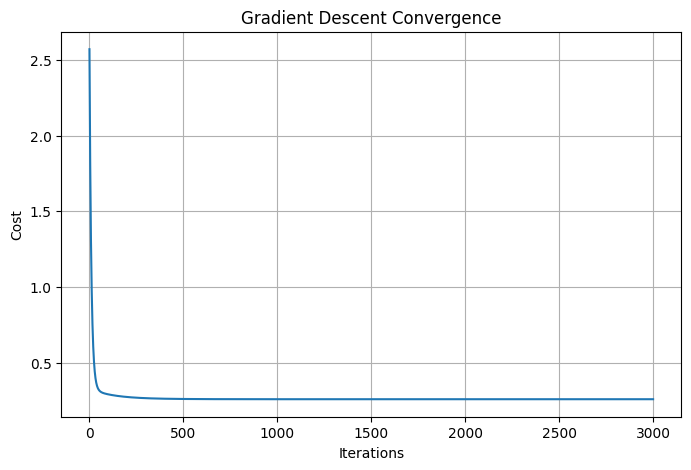

In [15]:
# Plot cost vs iterations

plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")

plt.grid(True)

plt.show()

In [16]:
# Predict house prices using testing data

y_pred = hypothesis(X_test_np, theta_final)

# Display actual and predicted values

print("Actual House Prices:")
print(y_test_np[:10])

print("\nPredicted House Prices:")
print(y_pred[:10])

print("\nPrediction Shape:", y_pred.shape)

Actual House Prices:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

Predicted House Prices:
[0.71918289 1.7639665  2.70973568 2.83886863 2.60446476 2.01179919
 2.64549256 2.16875513 2.74075742 3.91571895]

Prediction Shape: (4128,)


In [17]:
# Calculate Mean Squared Error manually

def calculate_mse(y_actual, y_predicted):

    mse = np.mean((y_actual - y_predicted) ** 2)

    return mse


# Calculate R2 Score manually

def calculate_r2(y_actual, y_predicted):

    ss_res = np.sum((y_actual - y_predicted) ** 2)

    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)

    r2 = 1 - (ss_res / ss_tot)

    return r2


# Evaluate our model

mse = calculate_mse(y_test_np, y_pred)

r2 = calculate_r2(y_test_np, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Test MSE:", mse)
print("Test R2 Score:", r2)

Model Evaluation Results
------------------------
Test MSE: 0.555903020369578
Test R2 Score: 0.5757789899182274


In [18]:
# Create Scikit-learn Linear Regression model

sk_model = LinearRegression()

# Train the model
sk_model.fit(X_train_scaled, y_train_np)

# Generate predictions
sk_predictions = sk_model.predict(X_test_scaled)

# Calculate MSE and R2 manually
sk_mse = calculate_mse(y_test_np, sk_predictions)

sk_r2 = calculate_r2(y_test_np, sk_predictions)

# Display results
print("Scikit-learn Model Results")
print("--------------------------")

print("Test MSE:", sk_mse)
print("Test R2 Score:", sk_r2)

print("\nScikit-learn Intercept:")
print(sk_model.intercept_)

print("\nScikit-learn Coefficients:")
print(sk_model.coef_)

Scikit-learn Model Results
--------------------------
Test MSE: 0.5558915986952442
Test R2 Score: 0.575787706032451

Scikit-learn Intercept:
2.071946937378881

Scikit-learn Coefficients:
[ 0.8544089   0.12254995 -0.29441905  0.33926976 -0.00230779 -0.04083034
 -0.89695604 -0.86986812]


In [19]:
# Compare coefficients of both models

comparison = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "From Scratch": theta_final[1:],
    "Scikit-learn": sk_model.coef_
})

print(comparison)

print("\nIntercept Comparison:")
print("From Scratch:", theta_final[0])
print("Scikit-learn:", sk_model.intercept_)

      Feature  From Scratch  Scikit-learn
0      MedInc      0.854513      0.854409
1    HouseAge      0.122572      0.122550
2    AveRooms     -0.294605     -0.294419
3   AveBedrms      0.339420      0.339270
4  Population     -0.002301     -0.002308
5    AveOccup     -0.040835     -0.040830
6    Latitude     -0.896707     -0.896956
7   Longitude     -0.869632     -0.869868

Intercept Comparison:
From Scratch: 2.071946937378877
Scikit-learn: 2.071946937378881


In [20]:
# Select only MedInc as the input feature

X_simple = df[["MedInc"]]
y_simple = df["MedHouseVal"]

# Split the dataset

X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

print("Training shape:", X_simple_train.shape)
print("Testing shape:", X_simple_test.shape
      )

Training shape: (16512, 1)
Testing shape: (4128, 1)


In [21]:
# Calculate mean and standard deviation from training data

simple_mean = X_simple_train.mean()
simple_std = X_simple_train.std()

# Standardize training and testing data

X_simple_train_scaled = (X_simple_train - simple_mean) / simple_std
X_simple_test_scaled = (X_simple_test - simple_mean) / simple_std

# Convert into NumPy arrays

X_simple_train_np = X_simple_train_scaled.to_numpy()
X_simple_test_np = X_simple_test_scaled.to_numpy()

y_simple_train_np = y_simple_train.to_numpy()
y_simple_test_np = y_simple_test.to_numpy()

print("Training shape:", X_simple_train_np.shape)
print("Testing shape:", X_simple_test_np.shape)

Training shape: (16512, 1)
Testing shape: (4128, 1)


In [22]:
# Add bias column to training data

X_simple_train_np = np.c_[
    np.ones(X_simple_train_np.shape[0]),
    X_simple_train_np
]

# Add bias column to testing data

X_simple_test_np = np.c_[
    np.ones(X_simple_test_np.shape[0]),
    X_simple_test_np
]

# Display shapes

print("Training shape:", X_simple_train_np.shape)
print("Testing shape:", X_simple_test_np.shape)

print("\nFirst 5 rows:")
print(X_simple_train_np[:5])

Training shape: (16512, 2)
Testing shape: (4128, 2)

First 5 rows:
[[ 1.         -0.32618613]
 [ 1.         -0.03584229]
 [ 1.          0.14469707]
 [ 1.         -1.01783356]
 [ 1.         -0.17148312]]


In [23]:
# Initialize theta values for simple regression

theta_simple_initial = np.zeros(X_simple_train_np.shape[1])

# Set learning parameters

learning_rate = 0.05
iterations = 3000

# Train the simple linear regression model

theta_simple, simple_cost_history = gradient_descent(
    X_simple_train_np,
    y_simple_train_np,
    theta_simple_initial,
    learning_rate,
    iterations
)

# Display results

print("Simple Linear Regression Training Completed!")

print("\nTheta Values:")
print(theta_simple)

print("\nInitial Cost:", simple_cost_history[0])
print("Final Cost:", simple_cost_history[-1])

Simple Linear Regression Training Completed!

Theta Values:
[2.07194694 0.79854375]

Initial Cost: 2.5745063625354083
Final Cost: 0.34957235850914115


In [24]:
# Predict using simple linear regression

y_simple_pred = hypothesis(
    X_simple_test_np,
    theta_simple
)

print("Actual House Prices:")
print(y_simple_test_np[:10])

print("\nPredicted House Prices:")
print(y_simple_pred[:10])

print("\nPrediction Shape:", y_simple_pred.shape)

Actual House Prices:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

Predicted House Prices:
[1.14958917 1.50606882 1.90393718 2.85059383 2.00663318 2.42165249
 2.57647226 1.99229181 2.45893168 3.84677436]

Prediction Shape: (4128,)


In [25]:
# Evaluate simple linear regression

simple_mse = calculate_mse(
    y_simple_test_np,
    y_simple_pred
)

simple_r2 = calculate_r2(
    y_simple_test_np,
    y_simple_pred
)

print("Simple Linear Regression Results")
print("--------------------------------")
print("Test MSE:", simple_mse)
print("Test R2 Score:", simple_r2)

Simple Linear Regression Results
--------------------------------
Test MSE: 0.7091157771765549
Test R2 Score: 0.45885918903846656


In [27]:
# Compare Simple and Multiple Linear Regression

final_comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression (From Scratch)",
        "Multiple Linear Regression (Scikit-learn)"
    ],
    "Number of Features": [1, 8, 8],
    "Test MSE": [
        simple_mse,
        mse,
        sk_mse
    ],
    "Test R2 Score": [
        simple_r2,
        r2,
        sk_r2
    ]
})

print(final_comparison.to_string(index=False))

                                    Model  Number of Features  Test MSE  Test R2 Score
                 Simple Linear Regression                   1  0.709116       0.458859
Multiple Linear Regression (From Scratch)                   8  0.555903       0.575779
Multiple Linear Regression (Scikit-learn)                   8  0.555892       0.575788


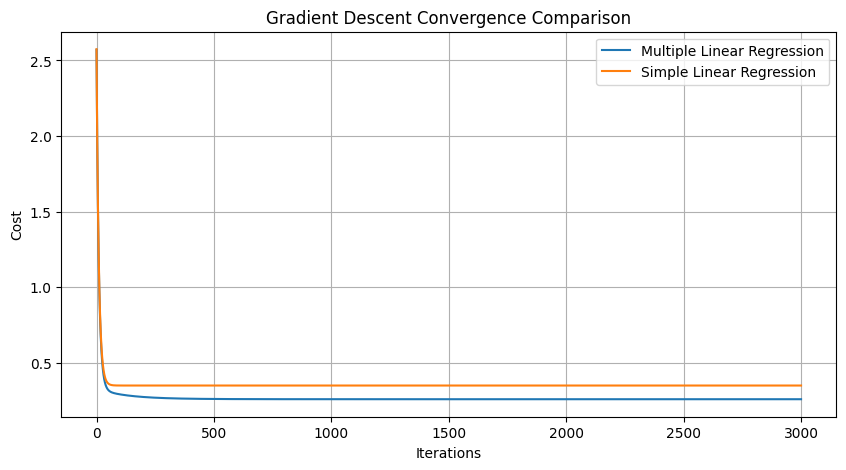

In [28]:
# Compare cost reduction of both models

plt.figure(figsize=(10, 5))

plt.plot(
    cost_history,
    label="Multiple Linear Regression"
)

plt.plot(
    simple_cost_history,
    label="Simple Linear Regression"
)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence Comparison")

plt.legend()
plt.grid(True)

plt.show()